# Out-of-core classification with partial_fit (Naive Bayes): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/applications/plot_out_of_core_classification.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/applications/plot_out_of_core_classification.html)).

**Scenario:** documents arrive in mini-batches of 1 000; every classifier is updated with
`partial_fit(X_batch, y_batch, classes=all_classes)` and scored on a fixed 1 000-document test set after each
batch, producing accuracy-versus-training-examples curves.

**Adaptations:**
- **Data substitution.** The example downloads the Reuters-21578 archive and hashes text with
  `HashingVectorizer(n_features=2**18)`. The network may be unavailable and Moxie has no text vectorizers,
  so the stream is replaced by synthetic bag-of-words counts: 9 000 documents over a 512-term vocabulary,
  Poisson document lengths (mean 21), 80% shared background vocabulary, class-specific multinomial word distributions drawn from a seeded
  Dirichlet, and about 25% positives (the example's "acq" vs rest binary task). The first 1 000 documents are the
  test set; the remaining 8 000 form 8 mini-batches, matching the example's `minibatch_size=1000`.
- The example's `NB Multinomial` is `MultinomialNB(alpha=0.01)` and is run unchanged on both sides.
  `SGD`, `Perceptron` and `Passive-Aggressive` run in the Python reference only: Moxie has no SGD-family
  linear models (GAP).
- **Extension beyond the example** (to cover the rest of the family on the same stream):
  `ComplementNB()`, `ComplementNB(norm=True)`, `BernoulliNB(binarize=0.0)`, a vector-alpha
  `MultinomialNB(alpha=<per-term array>, fit_prior=False)`, and
  `CategoricalNB(min_categories=4)` on counts clipped to {0,1,2,3}, all through the same `partial_fit` loop.
  A final weighted `fit` with `sample_weight` checks the batch-free path.
- The timing plots of the example are not reproduced (performance is not compared).

**Determinism:** deterministic (seeded data; Naive Bayes updates are closed-form count sums; the SGD-family
reference curves use the example's estimators, unseeded, and are shown but not compared).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("naive_bayes/plot_out_of_core_classification")

## 1. scikit-learn (Python reference)

Synthetic stream, then the example's mini-batch loop and accuracy plot.

Test set is 1000 documents (254 positive)


                         SGD accuracy after 8000 docs: 0.8670
                  Perceptron accuracy after 8000 docs: 0.8820
              NB Multinomial accuracy after 8000 docs: 0.9300
          Passive-Aggressive accuracy after 8000 docs: 0.8810
               NB Complement accuracy after 8000 docs: 0.9080
          NB Complement norm accuracy after 8000 docs: 0.9260
                NB Bernoulli accuracy after 8000 docs: 0.9320
 NB Multinomial alpha vector accuracy after 8000 docs: 0.9090
              NB Categorical accuracy after 8000 docs: 0.9260


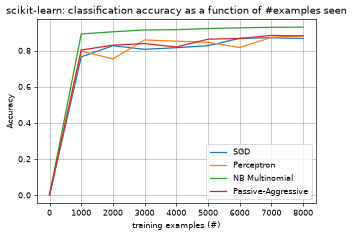

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron, SGDClassifier
from sklearn.naive_bayes import BernoulliNB, CategoricalNB, ComplementNB, MultinomialNB

rng = np.random.RandomState(0)
n_docs, n_terms = 9000, 512
y_all = (rng.uniform(size=n_docs) < 0.25).astype(int)
term_probs = rng.dirichlet(np.full(n_terms, 0.3), size=2)
term_probs = 0.2 * term_probs + 0.8 * rng.dirichlet(np.full(n_terms, 0.3))  # shared background vocabulary
lengths = rng.poisson(20, size=n_docs) + 1
X_all = np.stack([rng.multinomial(n, term_probs[c]) for n, c in zip(lengths, y_all)]).astype(np.float64)

X_test, y_test = X_all[:1000], y_all[:1000]
batches = [(X_all[s:s + 1000], y_all[s:s + 1000]) for s in range(1000, n_docs, 1000)]
all_classes = np.array([0, 1])
print("Test set is %d documents (%d positive)" % (len(y_test), sum(y_test)))

alpha_vector = np.linspace(0.01, 1.0, n_terms)
partial_fit_classifiers = {
    "SGD": SGDClassifier(max_iter=5),
    "Perceptron": Perceptron(),
    "NB Multinomial": MultinomialNB(alpha=0.01),
    "Passive-Aggressive": SGDClassifier(loss="hinge", penalty=None, learning_rate="pa1", eta0=1.0),
    # extension: the rest of the family on the same stream
    "NB Complement": ComplementNB(),
    "NB Complement norm": ComplementNB(norm=True),
    "NB Bernoulli": BernoulliNB(binarize=0.0),
    "NB Multinomial alpha vector": MultinomialNB(alpha=alpha_vector, fit_prior=False),
    "NB Categorical": CategoricalNB(min_categories=4),
}
def view(name, X):
    return np.minimum(X, 3) if name == "NB Categorical" else X

history = {name: [(0, 0)] for name in partial_fit_classifiers}
n_train = 0
for i, (X_train, y_train) in enumerate(batches):
    n_train += X_train.shape[0]
    for name, cls in partial_fit_classifiers.items():
        cls.partial_fit(view(name, X_train), y_train, classes=all_classes)
        history[name].append((cls.score(view(name, X_test), y_test), n_train))
for name, h in history.items():
    print("%28s accuracy after %d docs: %.4f" % (name, n_train, h[-1][0]))

plt.figure(figsize=(6, 4), dpi=60)
for name in ["SGD", "Perceptron", "NB Multinomial", "Passive-Aggressive"]:
    acc, n = zip(*history[name])
    plt.plot(n, acc, label=name)
plt.title("scikit-learn: classification accuracy as a function of #examples seen")
plt.xlabel("training examples (#)"); plt.ylabel("Accuracy"); plt.grid(True); plt.legend(loc="best")
plt.show()

nb_names = [n for n in partial_fit_classifiers if n.startswith("NB")]
sk = {name: partial_fit_classifiers[name] for name in nb_names}
weights = rng.uniform(0.0, 3.0, size=8000)
weighted = MultinomialNB(alpha=0.5).fit(X_all[1000:], y_all[1000:], sample_weight=weights)
nb.share(X_test=X_test, y_test=y_test, X_stream=X_all[1000:], y_stream=y_all[1000:],
         alpha_vector=alpha_vector, weights=weights)

## 2. Moxie (native Mojo)

The same loop: each batch is sliced from the shared stream, `partial_fit(..., classes=[0, 1])` updates every
model and `score` is recorded on the fixed test set. Learned attributes and test probabilities are saved after
the last batch.

In [3]:
%%mojo out_of_core
import numojo as nm
from numojo import NDArray, Shape, Item
from moxie.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB, CategoricalNB
from moxie_nb_io import load, load_ints, save, save_floats


def rows(X: NDArray[DType.float64], start: Int, stop: Int, clip: Bool = False) raises -> NDArray[DType.float64]:
    var out = nm.zeros[DType.float64](Shape(stop - start, X.shape[1]))
    for i in range(start, stop):
        for j in range(X.shape[1]):
            var value = X.item(i, j)
            out[Item(i - start, j)] = min(value, 3.0) if clip else value
    return out^


def labels(y: List[Int], start: Int, stop: Int) -> List[Int]:
    var out = List[Int]()
    for i in range(start, stop):
        out.append(y[i])
    return out^


def matrix(values: List[List[Float64]]) raises -> NDArray[DType.float64]:
    var out = nm.zeros[DType.float64](Shape(len(values), len(values[0])))
    for i in range(len(values)):
        for j in range(len(values[0])):
            out[Item(i, j)] = values[i][j]
    return out^


def vector(values: List[Float64]) raises -> NDArray[DType.float64]:
    var out = nm.zeros[DType.float64](Shape(len(values)))
    for i in range(len(values)):
        out[Item(i)] = values[i]
    return out^


def ints(values: List[Int]) raises -> NDArray[DType.float64]:
    var out = nm.zeros[DType.float64](Shape(len(values)))
    for i in range(len(values)):
        out[Item(i)] = Float64(values[i])
    return out^


def main() raises:
    var X_test = load("X_test")
    var y_test = load_ints("y_test")
    var X_stream = load("X_stream")
    var y_stream = load_ints("y_stream")
    var alpha_vector = load("alpha_vector")
    var X_test_cat = rows(X_test, 0, X_test.shape[0], clip=True)

    var multinomial = MultinomialNB(alpha=0.01)
    var complement = ComplementNB()
    var complement_norm = ComplementNB(norm=True)
    var bernoulli = BernoulliNB(binarize=0.0)
    var multinomial_vec = MultinomialNB(alpha_values=alpha_vector.copy(), fit_prior=False)
    var categorical = CategoricalNB(min_categories=4)
    var accuracy = List[Float64]()
    for b in range(8):
        var X_batch = rows(X_stream, 1000 * b, 1000 * (b + 1))
        var X_batch_cat = rows(X_stream, 1000 * b, 1000 * (b + 1), clip=True)
        var y_batch = labels(y_stream, 1000 * b, 1000 * (b + 1))
        _ = multinomial.partial_fit(X_batch, y_batch, classes=List[Int]([0, 1]))
        _ = complement.partial_fit(X_batch, y_batch, classes=List[Int]([0, 1]))
        _ = complement_norm.partial_fit(X_batch, y_batch, classes=List[Int]([0, 1]))
        _ = bernoulli.partial_fit(X_batch, y_batch, classes=List[Int]([0, 1]))
        _ = multinomial_vec.partial_fit(X_batch, y_batch, classes=List[Int]([0, 1]))
        _ = categorical.partial_fit(X_batch_cat, y_batch, classes=List[Int]([0, 1]))
        accuracy.append(multinomial.score(X_test, y_test))
        accuracy.append(complement.score(X_test, y_test))
        accuracy.append(complement_norm.score(X_test, y_test))
        accuracy.append(bernoulli.score(X_test, y_test))
        accuracy.append(multinomial_vec.score(X_test, y_test))
        accuracy.append(categorical.score(X_test_cat, y_test))
    save_floats("accuracy", accuracy)
    print("NB Multinomial accuracy after 8000 docs:", accuracy[len(accuracy) - 6])

    save("mn_class_count", multinomial.class_count_)
    save("mn_feature_count", multinomial.feature_count_)
    save("mn_feature_log_prob", multinomial.feature_log_prob_)
    save("mn_class_log_prior", vector(multinomial.class_log_prior_))
    save("mn_proba", matrix(multinomial.predict_proba(X_test)))
    save("mn_log_proba", matrix(multinomial.predict_log_proba(X_test)))
    save("mn_joint", matrix(multinomial.predict_joint_log_proba(X_test)))
    save("mn_pred", ints(multinomial.predict(X_test)))

    save("cn_feature_all", complement.feature_all_)
    save("cn_feature_log_prob", complement.feature_log_prob_)
    save("cn_joint", matrix(complement.predict_joint_log_proba(X_test)))
    save("cn_proba", matrix(complement.predict_proba(X_test)))
    save("cnn_feature_log_prob", complement_norm.feature_log_prob_)
    save("cnn_proba", matrix(complement_norm.predict_proba(X_test)))

    save("bn_feature_count", bernoulli.feature_count_)
    save("bn_feature_log_prob", bernoulli.feature_log_prob_)
    save("bn_class_log_prior", vector(bernoulli.class_log_prior_))
    save("bn_joint", bernoulli.predict_joint_log_proba(X_test))
    save("bn_proba", bernoulli.predict_proba(X_test))

    save("mv_feature_log_prob", multinomial_vec.feature_log_prob_)
    save("mv_class_log_prior", vector(multinomial_vec.class_log_prior_))
    save("mv_proba", matrix(multinomial_vec.predict_proba(X_test)))

    save("cat_class_count", categorical.class_count_)
    var counts = nm.zeros[DType.float64](Shape(len(categorical.category_count_), 2, 4))
    var logp = nm.zeros[DType.float64](Shape(len(categorical.feature_log_prob_), 2, 4))
    for f in range(len(categorical.category_count_)):
        for c in range(2):
            for k in range(4):
                counts[Item(f, c, k)] = categorical.category_count_[f].item(c, k)
                logp[Item(f, c, k)] = categorical.feature_log_prob_[f].item(c, k)
    save("cat_category_count", counts)
    save("cat_feature_log_prob", logp)
    save("cat_n_categories", ints(categorical.n_categories_))
    save("cat_joint", categorical.predict_joint_log_proba(X_test_cat))
    save("cat_proba", categorical.predict_proba(X_test_cat))

    var weights = load("weights")
    var w = List[Float64]()
    for i in range(weights.size):
        w.append(weights.item(i))
    var weighted = MultinomialNB(alpha=0.5)
    _ = weighted.fit(X_stream, y_stream, sample_weight=w^)
    save("w_class_count", weighted.class_count_)
    save("w_feature_log_prob", weighted.feature_log_prob_)
    save("w_proba", matrix(weighted.predict_proba(X_test)))

NB Multinomial accuracy after 8000 docs: 0.93


## 3. Side by side and parity

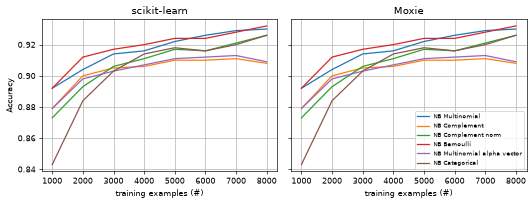

In [4]:
mx = nb.results["out_of_core"]
moxie_names = ["NB Multinomial", "NB Complement", "NB Complement norm", "NB Bernoulli",
               "NB Multinomial alpha vector", "NB Categorical"]
mx_acc = mx["accuracy"].reshape(8, len(moxie_names))
sk_acc = np.array([[history[name][b + 1][0] for name in moxie_names] for b in range(8)])
moxie_nb.side_by_side(sklearn={n: np.round(sk_acc[:, j], 4) for j, n in enumerate(moxie_names)},
                      moxie={n: np.round(mx_acc[:, j], 4) for j, n in enumerate(moxie_names)})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), dpi=60, sharey=True)
seen = np.arange(1, 9) * 1000
for j, name in enumerate(moxie_names):
    axes[0].plot(seen, sk_acc[:, j], label=name)
    axes[1].plot(seen, mx_acc[:, j], label=name)
axes[0].set_title("scikit-learn"); axes[1].set_title("Moxie")
for ax in axes:
    ax.set_xlabel("training examples (#)"); ax.grid(True)
axes[0].set_ylabel("Accuracy"); axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

In [5]:
REASON = ("count sums are exact; logs use Numax fdlibm (<= 1 ulp from glibc) and dot products over 512 terms "
          "differ from OpenBLAS summation order")
nb.compare("accuracy history after each batch (6 NB models x 8 batches)", sk_acc, mx_acc, exact=True)
m = sk["NB Multinomial"]
nb.compare("MultinomialNB class_count_", m.class_count_, mx["mn_class_count"], exact=True)
nb.compare("MultinomialNB feature_count_", m.feature_count_, mx["mn_feature_count"], exact=True)
nb.compare("MultinomialNB feature_log_prob_", m.feature_log_prob_, mx["mn_feature_log_prob"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("MultinomialNB class_log_prior_", m.class_log_prior_, mx["mn_class_log_prior"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("MultinomialNB predict", m.predict(X_test).astype(float), mx["mn_pred"], exact=True)
nb.compare("MultinomialNB predict_joint_log_proba", m.predict_joint_log_proba(X_test), mx["mn_joint"], rtol=1e-12, atol=1e-10, reason=REASON)
nb.compare("MultinomialNB predict_log_proba", m.predict_log_proba(X_test), mx["mn_log_proba"], rtol=1e-9, atol=1e-9,
           reason=REASON + "; normalization subtracts two ~1e3 joint terms")
nb.compare("MultinomialNB predict_proba", m.predict_proba(X_test), mx["mn_proba"], rtol=0, atol=1e-9,
           reason=REASON + "; exp of the normalized log-probabilities")
c = sk["NB Complement"]
nb.compare("ComplementNB feature_all_", c.feature_all_, mx["cn_feature_all"], exact=True)
nb.compare("ComplementNB feature_log_prob_", c.feature_log_prob_, mx["cn_feature_log_prob"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("ComplementNB predict_joint_log_proba", c.predict_joint_log_proba(X_test), mx["cn_joint"], rtol=1e-12, atol=1e-10, reason=REASON)
nb.compare("ComplementNB predict_proba", c.predict_proba(X_test), mx["cn_proba"], rtol=0, atol=1e-9, reason=REASON)
cn = sk["NB Complement norm"]
nb.compare("ComplementNB(norm=True) feature_log_prob_", cn.feature_log_prob_, mx["cnn_feature_log_prob"], rtol=1e-12, atol=1e-15, reason=REASON)
nb.compare("ComplementNB(norm=True) predict_proba", cn.predict_proba(X_test), mx["cnn_proba"], rtol=0, atol=1e-9, reason=REASON)
b = sk["NB Bernoulli"]
nb.compare("BernoulliNB feature_count_", b.feature_count_, mx["bn_feature_count"], exact=True)
nb.compare("BernoulliNB feature_log_prob_", b.feature_log_prob_, mx["bn_feature_log_prob"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("BernoulliNB class_log_prior_", b.class_log_prior_, mx["bn_class_log_prior"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("BernoulliNB predict_joint_log_proba", b.predict_joint_log_proba(X_test), mx["bn_joint"], rtol=1e-12, atol=1e-10, reason=REASON)
nb.compare("BernoulliNB predict_proba", b.predict_proba(X_test), mx["bn_proba"], rtol=0, atol=1e-9, reason=REASON)
v = sk["NB Multinomial alpha vector"]
nb.compare("MultinomialNB(alpha=vector, fit_prior=False) feature_log_prob_", v.feature_log_prob_, mx["mv_feature_log_prob"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("MultinomialNB(alpha=vector, fit_prior=False) class_log_prior_", v.class_log_prior_, mx["mv_class_log_prior"], rtol=1e-15, reason=REASON)
nb.compare("MultinomialNB(alpha=vector) predict_proba", v.predict_proba(X_test), mx["mv_proba"], rtol=0, atol=1e-9, reason=REASON)
k = sk["NB Categorical"]
Xc = np.minimum(X_test, 3)
nb.compare("CategoricalNB class_count_", k.class_count_, mx["cat_class_count"], exact=True)
nb.compare("CategoricalNB category_count_", np.stack(k.category_count_), mx["cat_category_count"], exact=True)
nb.compare("CategoricalNB feature_log_prob_", np.stack(k.feature_log_prob_), mx["cat_feature_log_prob"], rtol=1e-13, atol=1e-13, reason=REASON)
nb.compare("CategoricalNB n_categories_", k.n_categories_.astype(float), mx["cat_n_categories"], exact=True)
nb.compare("CategoricalNB predict_joint_log_proba", k.predict_joint_log_proba(Xc), mx["cat_joint"], rtol=1e-12, atol=1e-10, reason=REASON)
nb.compare("CategoricalNB predict_proba", k.predict_proba(Xc), mx["cat_proba"], rtol=0, atol=1e-9, reason=REASON)
nb.compare("weighted MultinomialNB.fit class_count_", weighted.class_count_, mx["w_class_count"], rtol=1e-13,
           reason="sum of 8000 uniform weights; sklearn sums with a BLAS dot (Y.T @ X), Moxie sequentially")
nb.compare("weighted MultinomialNB.fit feature_log_prob_", weighted.feature_log_prob_, mx["w_feature_log_prob"], rtol=1e-12, atol=1e-12, reason=REASON)
nb.compare("weighted MultinomialNB.fit predict_proba", weighted.predict_proba(X_test), mx["w_proba"], rtol=0, atol=1e-9, reason=REASON)
nb.note("SGD, Perceptron, Passive-Aggressive", "GAP", "moxie.linear_model has no SGDClassifier/Perceptron (linear_model family).")
nb.note("Reuters stream + HashingVectorizer", "ADAPTED", "download and text hashing replaced by seeded synthetic bag-of-words counts; "
        "Moxie has no feature_extraction.text.")
nb.note("sparse CSR input", "GAP", "the example feeds scipy.sparse CSR batches; Moxie NB accepts dense List/NDArray only "
        "(documented deferral in docs/naive_bayes/scope.md).")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
accuracy history after each batch (6 NB models x 8 batches),PASS,"(8, 6)","(8, 6)",,,exact,0 mismatches,
MultinomialNB class_count_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
MultinomialNB feature_count_,PASS,"(2, 512)","(2, 512)",,,exact,0 mismatches,
MultinomialNB feature_log_prob_,PASS,"(2, 512)","(2, 512)",1.07e-14,2.5e-15,"rtol=1e-13, atol=1e-13",,count sums are exact; logs use Numax fdlibm (<= 1 ulp from glibc) and dot products over 512 terms differ from OpenBLAS summation order
MultinomialNB class_log_prior_,PASS,"(2,)","(2,)",0,0,"rtol=1e-13, atol=1e-13",,count sums are exact; logs use Numax fdlibm (<= 1 ulp from glibc) and dot products over 512 terms differ from OpenBLAS summation order
MultinomialNB predict,PASS,"(1000,)","(1000,)",,,exact,0 mismatches,
MultinomialNB predict_joint_log_proba,PASS,"(1000, 2)","(1000, 2)",3.41e-13,2.16e-15,"rtol=1e-12, atol=1e-10",,count sums are exact; logs use Numax fdlibm (<= 1 ulp from glibc) and dot products over 512 terms differ from OpenBLAS summation order
MultinomialNB predict_log_proba,PASS,"(1000, 2)","(1000, 2)",3.69e-13,2.08e-11,"rtol=1e-09, atol=1e-09",,count sums are exact; logs use Numax fdlibm (<= 1 ulp from glibc) and dot products over 512 terms differ from OpenBLAS summation order; normalization subtracts two ~1e3 joint terms
MultinomialNB predict_proba,PASS,"(1000, 2)","(1000, 2)",7.14e-14,3.7e-13,"rtol=0, atol=1e-09",,count sums are exact; logs use Numax fdlibm (<= 1 ulp from glibc) and dot products over 512 terms differ from OpenBLAS summation order; exp of the normalized log-probabilities
ComplementNB feature_all_,PASS,"(512,)","(512,)",,,exact,0 mismatches,
